In [49]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

DERIVED = Path("derived")
VISUALIZATIONS = Path("visualizations")

In [15]:
data = pd.read_csv(DERIVED / 'data24-26.csv')

In [62]:
%config InlineBackend.figure_format = 'retina'
plt.rcParams['savefig.dpi'] = 300

PITCH_COLORS = {
    'FF': '#d22d49', 'SI': '#fe9d00', 'FC': '#933f2c', 'SL': '#eee716', 'ST': '#ddb33a',
    'SV': '#93afd4', 'CU': '#00d1ed', 'CH': '#1dbe3a', 'FS': '#3bacac', 'FO': '#55ccab',
    'KN': '#3c44cd'}

def movement_plot(data, name, year):
    df = data[(data['name'] == name)& (data['year'] == year)].sort_values('pitch_usage', ascending=False)
    if df.empty:
        raise ValueError(f'No rows for {name} in {year}')
    hand = df['hand'].iloc[0]

    # pitcher_break_x is unsigned. league_break_x is signed (< 0 = arm side, > 0 = glove side) and
    # diff_x = pitcher's break toward the league direction minus |league_break_x|, so
    # |league_break_x| + diff_x < 0 means this pitch breaks the opposite way from the league average.
    league_arm = np.where(df['league_break_x'] < 0, 1, -1)
    league_arm = np.where(df['league_break_x'].isna(), 1, league_arm)  # forkballs has no league avg: arm side
    toward_league = df['league_break_x'].abs() + df['diff_x']
    same_side = np.where(toward_league.isna() | (toward_league >= 0), 1, -1)
    # Pitcher's view: 1B on the left, 3B on the right, so a RHP's arm side is +x and a LHP's is -x.
    # Determines correct side for pitch break
    x = df['pitcher_break_x'] * league_arm * same_side * (1 if hand == 'R' else -1)
    z = df['pitcher_break_z_induced']

    fig, ax = plt.subplots(figsize=(7, 7))
    for r in [6, 12, 18, 24]:
        ax.add_patch(plt.Circle((0, 0), r, fill=False, color='gray',ls='-', lw=0.8, alpha=0.6))
    ax.axhline(0, color='gray', lw=0.8)
    ax.axvline(0, color='gray', lw=0.8)

    for (_, row), xi, zi in zip(df.iterrows(), x, z):
        ax.scatter(xi, zi, s=row['pitch_usage'] * 40, color=PITCH_COLORS.get(row['pitch_type'], 'gray'),
                   alpha=0.8, edgecolor='black', zorder=3,
                   label=f"{row['pitch_type']}  {row['pitch_usage']:.0f}%  {row['avg_speed']:.1f} mph ({xi}, {zi})")

    ax.set_xlim(-26, 26)
    ax.set_ylim(-26, 26)
    ax.set_aspect('equal')
    ax.set_xlabel('Horizontal break (in)   ← 1B  |  3B →')
    ax.set_ylabel('Induced vertical break (in)')
    ax.set_title(f'{name} ({hand}HP) – {year} Movement Profile')
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), markerscale=0.4, labelspacing=1.2, frameon=False)
    plt.tight_layout()
    return fig, ax



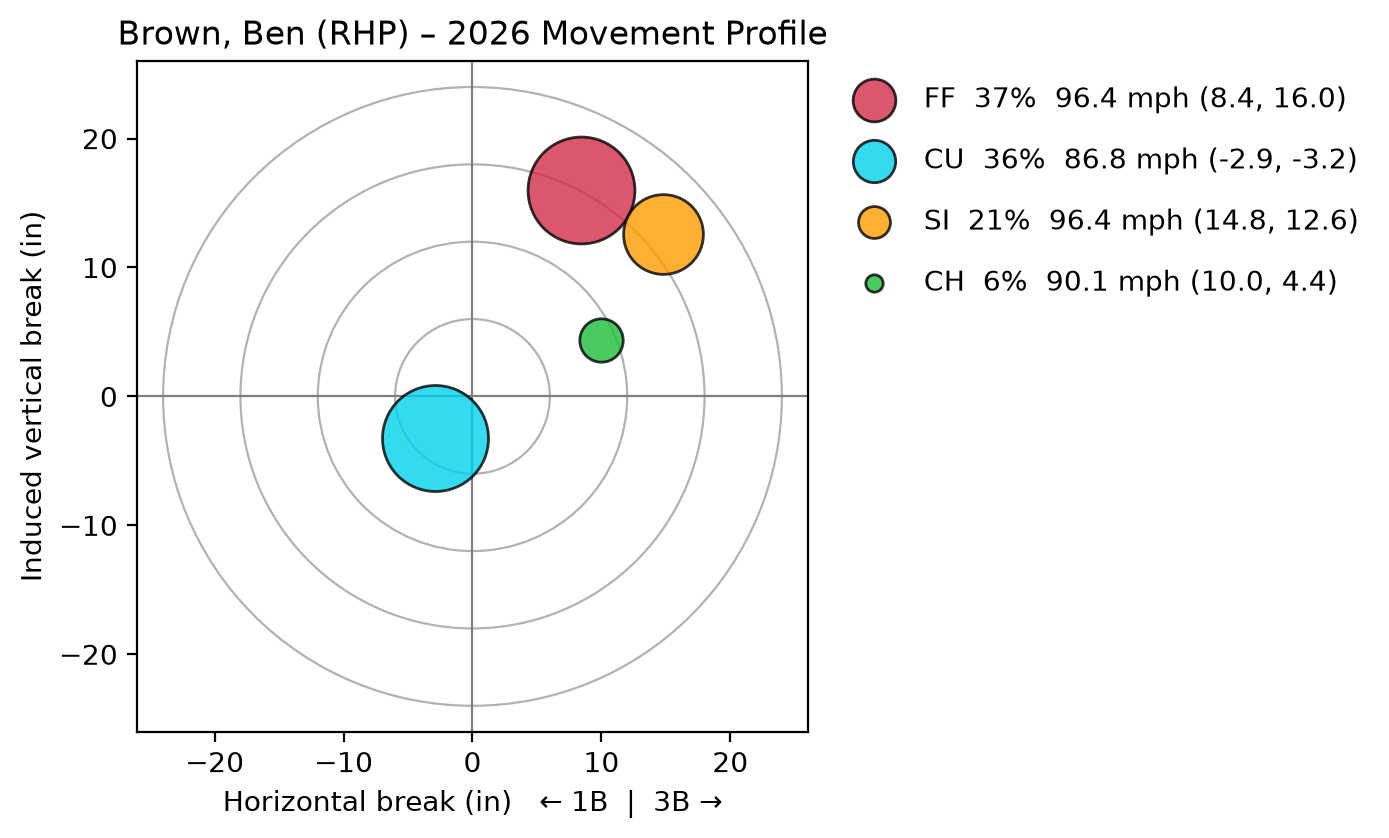

In [63]:

movement_plot(data, 'Brown, Ben', 2026)
plt.savefig(VISUALIZATIONS / "Ben Brown 2026.png")
plt.show()

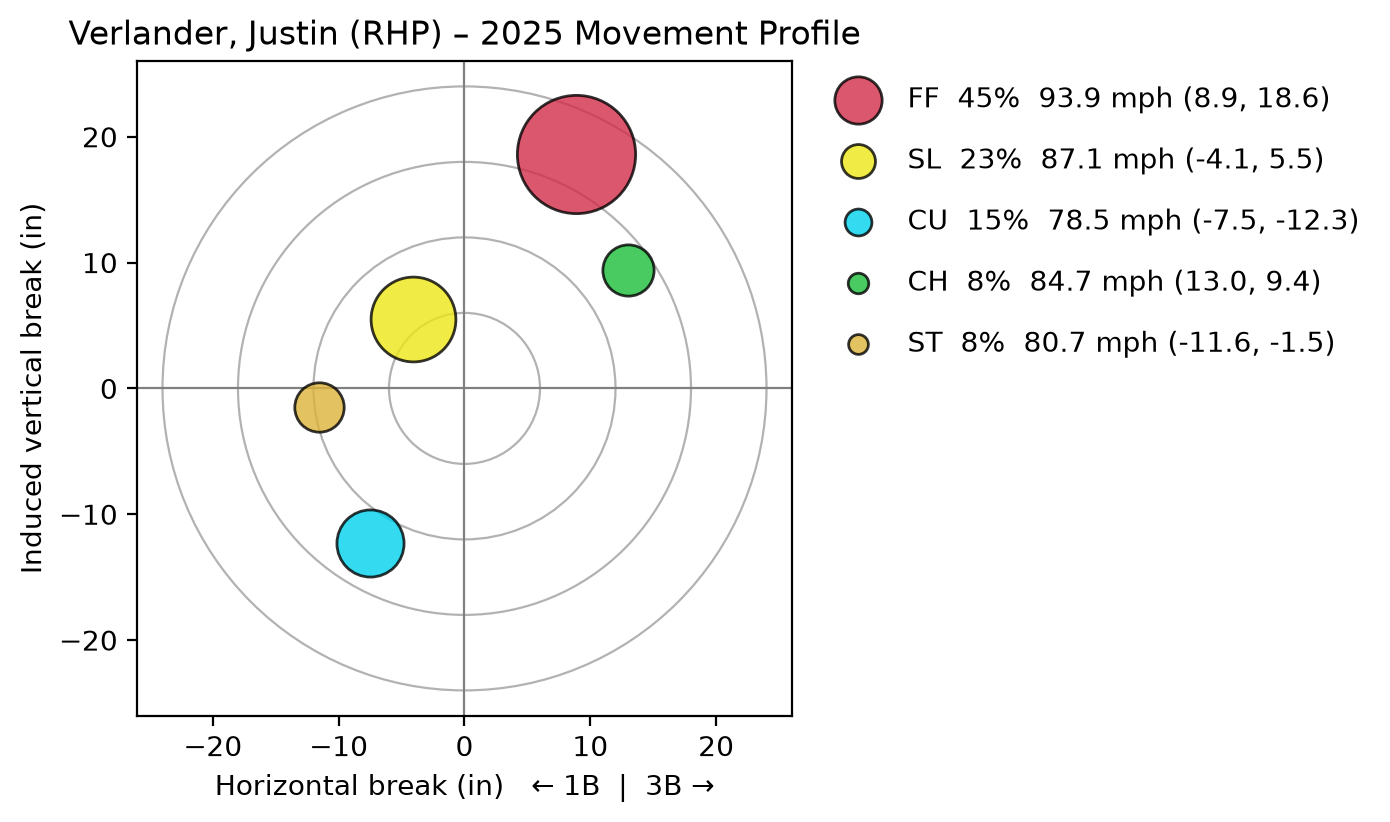

In [64]:
movement_plot(data,'Verlander, Justin', 2025)
plt.show()

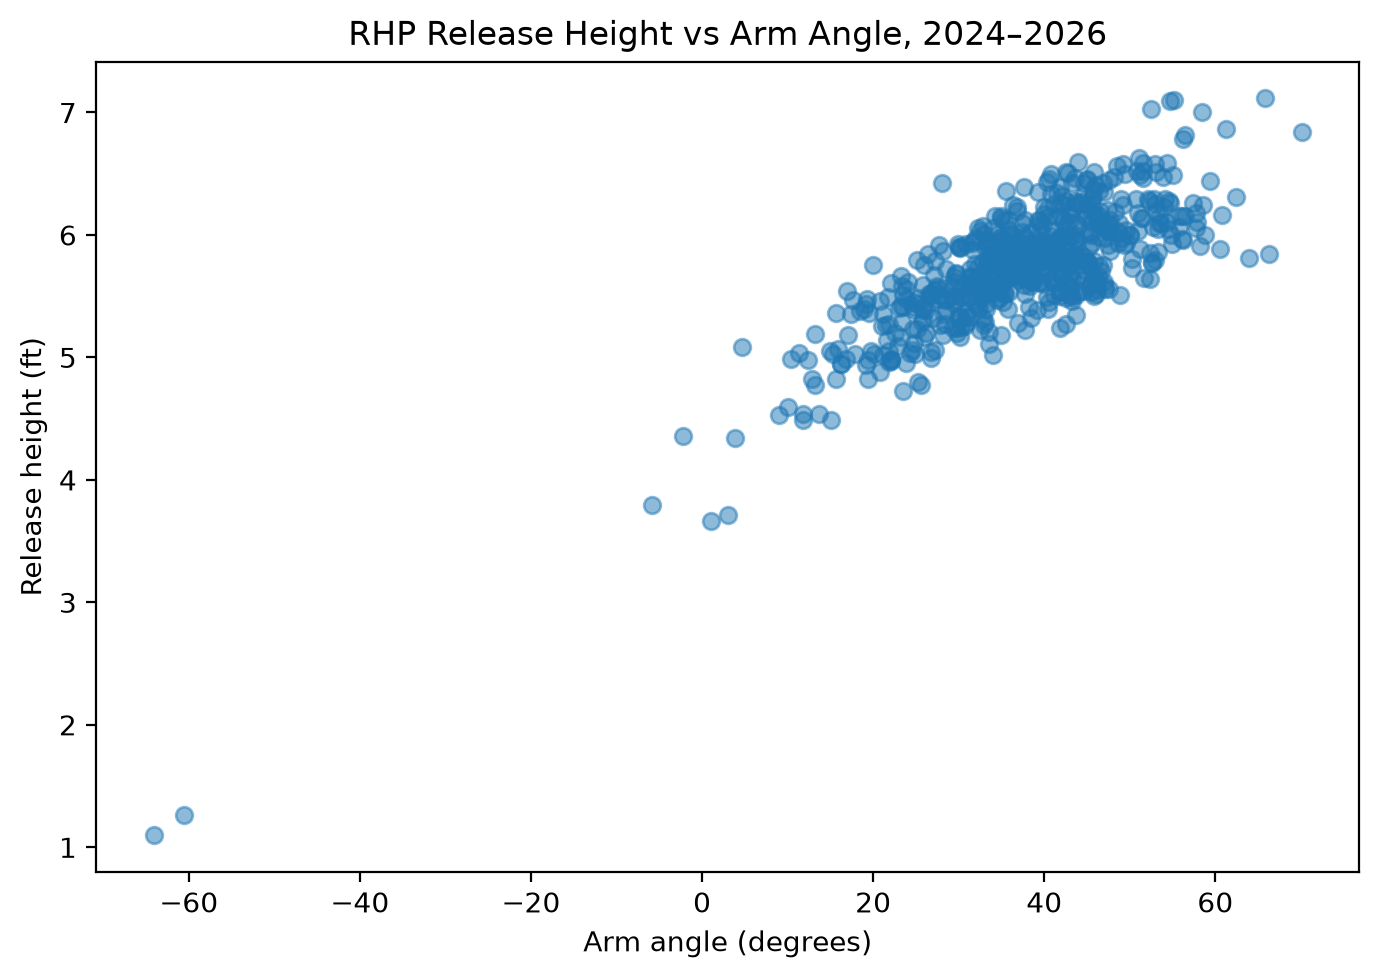

In [42]:
rhp = data[data['hand'] == 'R'].drop_duplicates(subset=['id', 'year'])
lhp = data[data['hand'] == 'L'].drop_duplicates(subset=['id', 'year'])

throwing_hand = [rhp,lhp]
# 
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(throwing_hand[0]['ball_angle'], throwing_hand[0]['release_ball_z'], alpha=0.5)
ax.set_xlabel('Arm angle (degrees)')
ax.set_ylabel('Release height (ft)')
ax.set_title('RHP Release Height vs Arm Angle, 2024–2026')
plt.tight_layout()
plt.show()

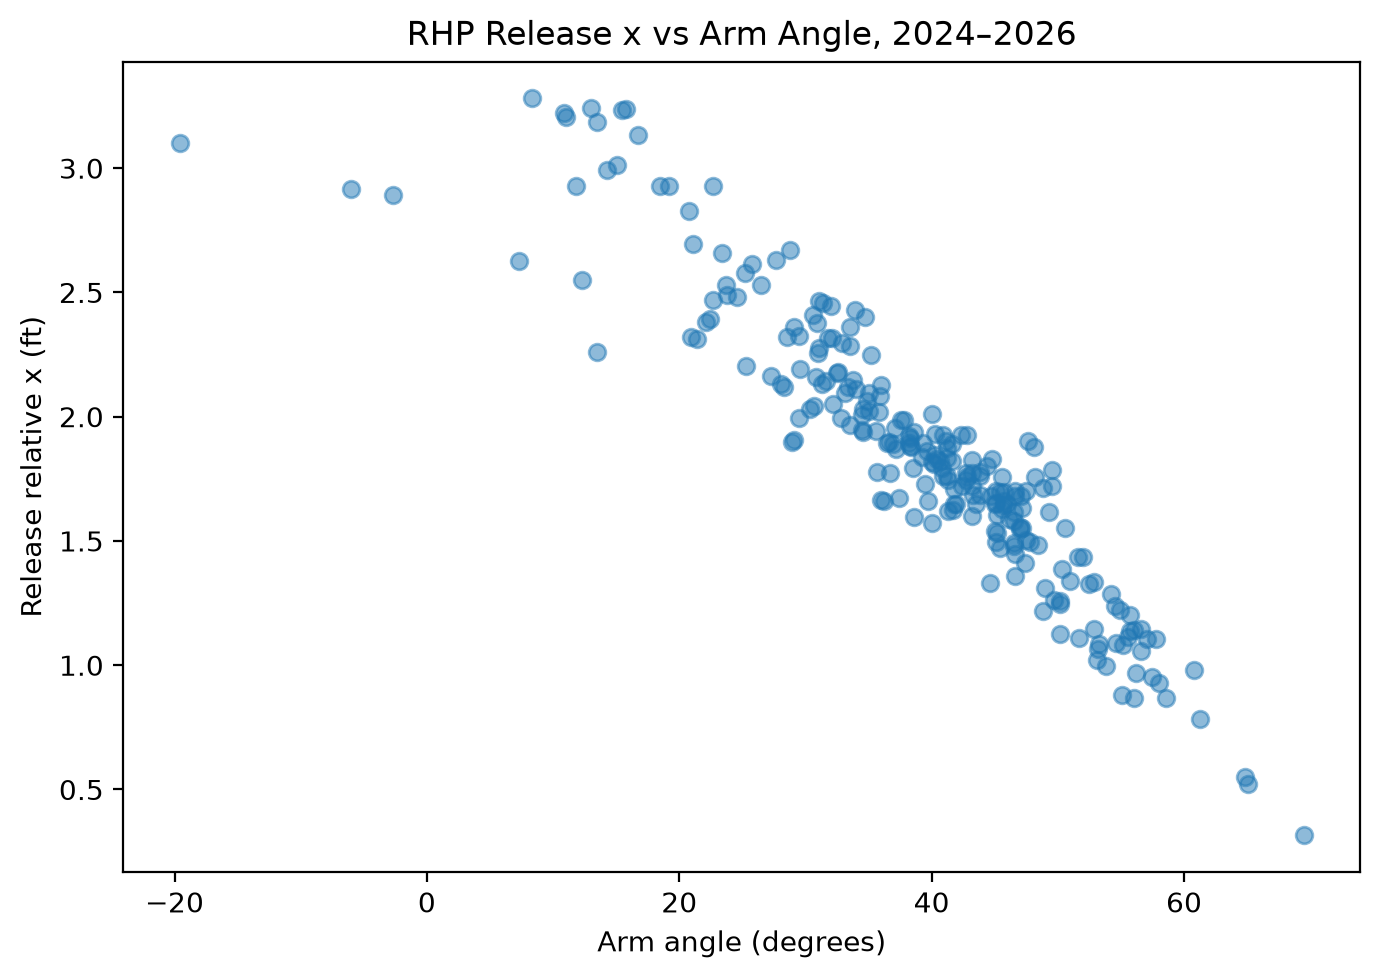

In [39]:
rhp = data[data['hand'] == 'R'].drop_duplicates(subset=['id', 'year'])
lhp = data[data['hand'] == 'L'].drop_duplicates(subset=['id', 'year'])

throwing_hand = [rhp,lhp]
# 
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(throwing_hand[1]['ball_angle'], throwing_hand[1]['relative_release_ball_x'], alpha=0.5)
ax.set_xlabel('Arm angle (degrees)')
ax.set_ylabel('Release relative x (ft)')
ax.set_title('RHP Release x vs Arm Angle, 2024–2026')
plt.tight_layout()
plt.show()

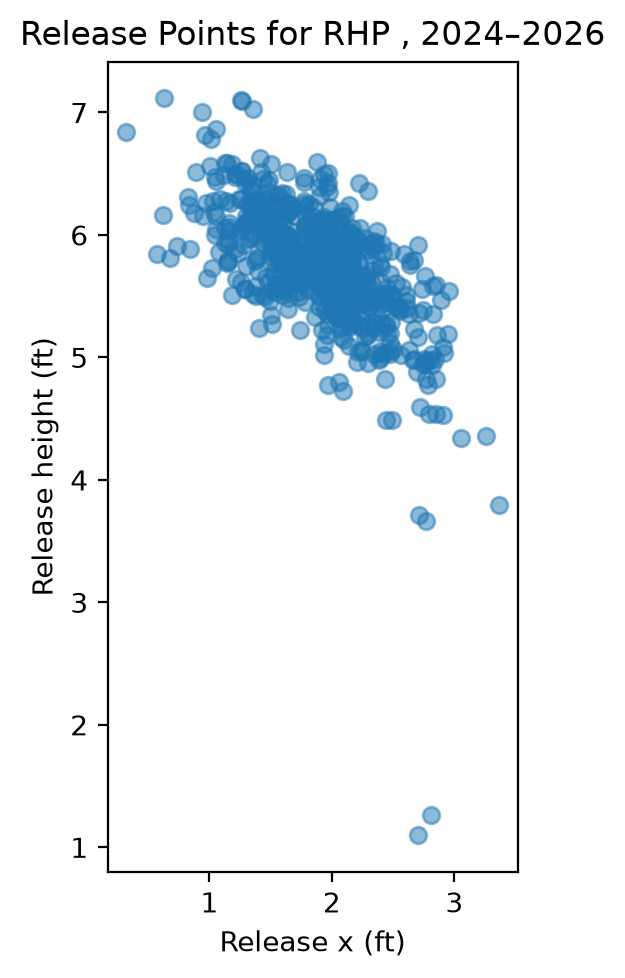

In [47]:
rhp = data[data['hand'] == 'R'].drop_duplicates(subset=['id', 'year'])
lhp = data[data['hand'] == 'L'].drop_duplicates(subset=['id', 'year'])

throwing_hand = [rhp,lhp]
# 
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(abs(throwing_hand[0]['relative_release_ball_x']), throwing_hand[0]['release_ball_z'],alpha=0.5)
ax.set_aspect('equal')
ax.set_xlabel('Release x (ft)')
ax.set_ylabel('Release height (ft)')
ax.set_title('Release Points for RHP , 2024–2026')
plt.tight_layout()
plt.show()